# Lab. 1: Tools - Exercises  

## Exercise 1.1: Use another popular dataset such as CIFAR-10

* The CIFAR-10 dataset (https://www.cs.toronto.edu/~kriz/cifar.html) consists of 60000 32x32 colour images in 10 classes (*airplane*, *automobile*, *bird*, *cat*, *deer*, *dog*, *frog*, *horse*, *ship* and *truck*), with 6000 images per class. 

* There are 50000 training images and 10000 test images.

* The dataset is divided into five training batches and one test batch, each with 10000 images. The test batch contains exactly 1000 randomly-selected images from each class. The training batches contain the remaining images in random order, but some training batches may contain more images from one class than another. Between them, the training batches contain exactly 5000 images from each class.

* The classes are completely mutually exclusive. There is no overlap between automobiles and trucks. "Automobile" includes sedans, SUVs, things of that sort. "Truck" includes only big trucks. Neither includes pickup trucks.

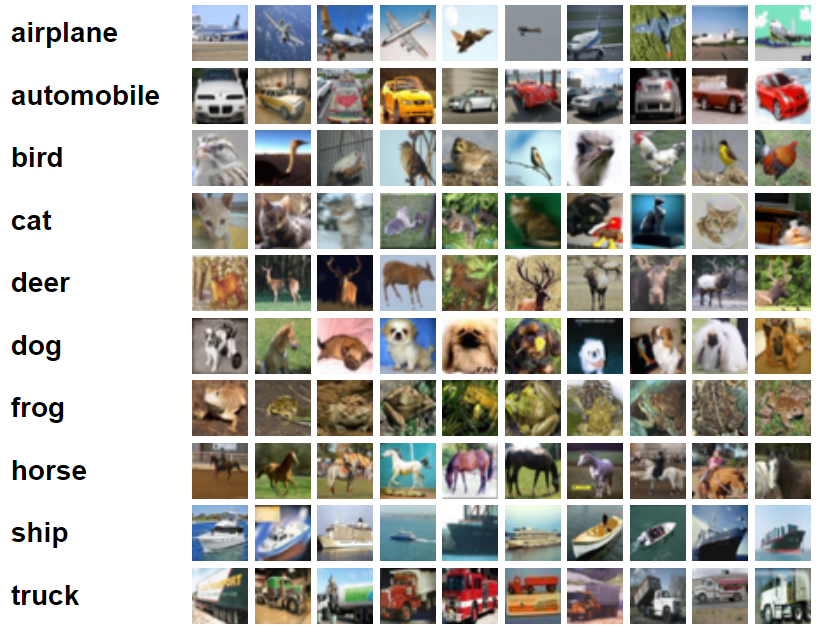

<!-- Source: https://machinelearningmastery.com/how-to-develop-a-cnn-from-scratch-for-cifar-10-photo-classification --> 
<!-- https://www.kaggle.com/code/vassiliskrikonis/cifar-10-analysis-with-a-neural-network -->

Like MNIST, the CIFAR-10 dataset is included in Keras, so it is very easy to work with.

#### Load dataset

In [1]:
# example of loading the cifar10 dataset
from keras.datasets import cifar10

# load dataset
(train_x, train_y), (test_x, test_y) = cifar10.load_data()

I0000 00:00:1793801250.696679  339560 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
print(f"train: x={train_x.shape}, y={train_y.shape}")
print(f"test: x={test_x.shape}, y={test_y.shape}")

train: x=(50000, 32, 32, 3), y=(50000, 1)
test: x=(10000, 32, 32, 3), y=(10000, 1)


#### Prepare dataset

* Left as an exercise...

In [ ]:
train_x = train_x.reshape((50000, 32 * 32 * 3)) #Aplanar
test_x = test_x.reshape((10000, 32 * 32 * 3))

train_x = train_x.astype("float32") / 255# Normalizar(importante en float32)
test_x = test_x.astype("float32") / 255

from keras.utils import to_categorical
train_y = to_categorical(train_y)# El modelo categorical_crossentropy requiere que las etiquetas estén en formato one-hot
test_y = to_categorical(test_y)


#### Define and train model

* Left as an exercise...
* Use only dense networks, not convolutional networks.

In [ ]:
import keras
from keras import layers

model = keras.Sequential()
model.add(layers.Input(shape=(32 * 32 * 3, )))
model.add(layers.Dense(512, activation="relu"))
model.add(layers.Dense(10, activation="softmax"))

model.summary()# Todo correcto en principio
model.compile(optimizer="adam", 
              loss="categorical_crossentropy",
              metrics=["accuracy"])

model.fit(train_x, train_y, epochs=5, batch_size=64)


W0000 00:00:1793801256.030392  339560 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,578,506 (6.02 MB)

 Trainable params: 1,578,506 (6.02 MB)

 Non-trainable params: 0 (0.00 B)

... (696 outputs left out)


768/782 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4494 - loss: 1.5488


774/782 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4493 - loss: 1.5488


780/782 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4494 - loss: 1.5492


782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.4495 - loss: 1.5490


## Exercise 1.2. Train your models in a GPUs

* Follow the instructions on how to install the libraries and drivers needed to use your local GPU.
* Train the models over the GPU and compare the differences with the CPU.
* Use also online access to GPUs such as those provided by Google Colab: https://colab.research.google.com/

In [ ]:
import tensorflow as tf
print("Num GPUs Available: ", len(tf.config.list_physical_devices("GPU")))
print(f"GPU Devices: {tf.config.list_physical_devices("GPU")}")# El nombre es raro pero la GPU en uso es la entiendo 0 del PC

Num GPUs Available:  1
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Exercise 1.3: Train your models in a supercomputing facilty as CESGA.

* Ask your professor for a students CESGA account.
* We don't have many available so in principle we will arrange them by practice pairs.
* Give your teacher the details of each pair and he/she will give you the details of the account.
* Follow the instructions on how to enter CESGA and train your models.

__Note__:
* The idea is to be doing these exercises throughout these weeks, while we do not publish the first practice.
* Exercises are not evaluable, it is a way for you to check that you have all the available tools well configured.
* It is not mandatory to use a CESGA account, it is just another option to take into account and of which you can take advantage.